# 06 · Examine the clean three-seed metadata NN

Reproduce the network protocol and inspect its saved fitting histories, stopping decisions, seed stability and equal-mean ensemble on the same retained OOF records.

Read the stages in numerical order. Training uses separate, explicitly invoked runners; executing this notebook only loads development data and saved artifacts.

Original notebooks, images, checkpoints and results remain available. The reserved test is outside this workflow.

**Original methods and figure reference:** [06_metadata_neural_network.ipynb](../Subset/06_metadata_neural_network.ipynb). Read [method coverage](METHOD_COVERAGE.md) for retained methods and declared adaptations.

## Load the frozen clean development dataset

In [1]:
NOTEBOOK_STAGE = '06_metadata_neural_network'
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from melanoma_detection.development_dataset import load_development_dataset, load_preserved_inner_memberships
from melanoma_detection.dedup_workflow import load_context, latest_evaluation, load_clean_scores, load_image_report, load_uncertainty_report, read_json, project_path, DIRECTORY, METADATA_SUITE, UNCERTAINTY
get_ipython().run_line_magic("matplotlib", "inline")
MANIFEST = "data/subset/processed/dedup_v1/dataset_manifest.json"
data, dataset_identity = load_development_dataset(ROOT, dataset_manifest=MANIFEST)
context = load_context(ROOT)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
FIGURE_DIR = ROOT / DIRECTORY / "figures" / NOTEBOOK_STAGE
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def finish_figure(figure, filename):
    if not filename or Path(filename).name != filename:
        raise ValueError("Figure name must be a simple stem.")
    figure.savefig(FIGURE_DIR / (filename + ".png"), dpi=180, bbox_inches="tight")
    figure.savefig(FIGURE_DIR / (filename + ".pdf"), bbox_inches="tight")
    plt.show()
    plt.close(figure)

_score_bundle = None
def score_bundle():
    global _score_bundle
    if _score_bundle is None:
        _score_bundle = load_clean_scores(ROOT)
    return _score_bundle
display(pd.DataFrame([{"Images": len(data), "Malignant images": int(data.target.sum()),
    "Patients": data.patient_id.nunique(), "Malignant patients": data.loc[data.target.eq(1), "patient_id"].nunique()}]))
display(Markdown("**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training."))

def show_saved_table(relative, limit=30):
    path = project_path(ROOT, relative)
    if not path.exists():
        display(Markdown("**Pending:** " + relative + ". No results are inferred from unfinished runs."))
        return pd.DataFrame()
    table = pd.read_csv(path)
    display(table.head(limit))
    if len(table) > limit:
        display(Markdown(f"Showing {limit} of {len(table)} rows; the complete CSV is saved."))
    return table

def comparison_table():
    evaluation = latest_evaluation(ROOT)
    if "output_directory" not in evaluation:
        display(Markdown("**Pending:** clean evaluation has not been generated."))
        return pd.DataFrame()
    path = project_path(ROOT, evaluation["output_directory"] + "/model_comparison.csv")
    return pd.read_csv(path)

def model_chart(table, title):
    if table.empty:
        display(Markdown("**Pending:** no verified scores are available for this stage."))
        return
    table = table.sort_values("average_precision")
    fig, ax = plt.subplots(figsize=(9, max(3.2, .38 * len(table) + 1.5)), layout="constrained")
    ax.barh(table.model, table.average_precision, color="#276b91")
    ax.set(title=title, xlabel="Unweighted mean outer-fold average precision", xlim=(0, max(.1, float(table.average_precision.max()) * 1.25)))
    finish_figure(fig, "model_comparison_ap")

def pilot_report(run_id):
    directory = ROOT / "results/image_d1_runs" / run_id
    path = directory / "summary.json"
    summary = read_json(path) if path.exists() else {"status": "pending"}
    if summary.get("status") == "complete":
        manifest = read_json(directory / "run_manifest.json")
        if manifest["dataset_identity"] != dataset_identity:
            raise ValueError("Pilot belongs to another dataset.")
        from melanoma_detection.development_dataset import sha256_file
        for relative, digest in summary["artifact_sha256"].items():
            artifact = (directory / relative).resolve()
            if not artifact.is_relative_to(directory.resolve()) or sha256_file(artifact) != digest:
                raise ValueError("Completed pilot artifact changed.")
    return directory, summary


,Images,Malignant images,Patients,Malignant patients
0,6706,127,422,88


**Dataset:** `dedup_v1` · original patient folds · development records only. This notebook reads saved results and starts no training.

## 1. Explain architecture, preprocessing and optimisation

The model is a 32-unit dense layer, ReLU, 20% dropout and one output logit. Training median/scaling prepare age; training one-hot categories prepare sex/site. AdamW uses learning rate 0.001, weight decay 0.001 and batches of 128, with unweighted BCE loss. Seeds 42, 142 and 242 are all retained with equal averaging; there is no favourable-seed selection.

In [2]:
import json
from melanoma_detection.metadata_evaluation import decision_metrics
from melanoma_detection.dedup_notebook_metadata import (
    LABELS, COLORS, saved_metadata, metric_table, curve_figure, metric_bar_figure,
    cutoff_table, confusion_figure, estimator_diagnostics, reliability_table,
    decision_intervals, subgroup_diagnostics, save_metadata_table,
)
bundle = score_bundle()
frame, scores = bundle["expected"], bundle["scores"]
meta = saved_metadata(ROOT, bundle)
display(pd.DataFrame([{"Dataset identity": bundle["identity"]["dataset_identity"],
    "New CPU fits": meta["receipt"]["executed_fits"], "Reused clean fits": meta["receipt"]["reused_fits"],
    "Images with matching predictions": len(frame), "Reserved test loaded": False}]))

spec = meta["core"]["specification"]["neural_network"]
display(pd.DataFrame([spec]).T)
epochs = pd.read_csv(meta["base"] / "epochs.csv")
history = pd.read_csv(meta["base"] / "history.csv")
names = ["spline_raw", "nn_seed_42", "nn_seed_142", "nn_seed_242", "metadata_nn_mean"]
metrics = metric_table(frame, scores, names)

,Dataset identity,New CPU fits,Reused clean fits,Images with matching predictions,Reserved test loaded
0,0562e7bb898ab69d2e5ac7fcf50bf6e9b80663362af4ae...,695,60,6706,False


,0
base_seeds,"[42, 142, 242]"
hidden_units,32
dropout,0.2
max_epochs,100
min_epochs,10
patience,12
minimum_improvement,0.00001
batch_size,128
learning_rate,0.001
weight_decay,0.001


## 2. Verify patient-safe stopping and fresh outer refits

For each seed/fold, a different preserved training fold supplies stopping labels: (outer fold + 1 + seed index) modulo 5. Best stopping BCE chooses duration; at least ten epochs are attempted with patience 12. That duration is then used by a fresh preprocessor and network fitted on all four outer-training folds. Outer labels never select epochs. These runs vary both seed and stopping membership, not independent datasets.

In [3]:
display(epochs[["base_seed", "outer_fold", "training_seed", "stop_fold", "selected_epochs", "attempted_stopping_epochs", "stop_log_loss", "epoch_fit_patients", "epoch_stop_patients", "score_patients"]].round(5))
checks = []
for fold in range(5):
    members = pd.read_csv(meta["base"] / f"fold_{fold}/selection_memberships.csv")
    for seed, rows in members.groupby("base_seed"):
        fit = set(rows.loc[rows.role.eq("epoch_fitting"), "patient_id"])
        stop = set(rows.loc[rows.role.eq("epoch_stopping"), "patient_id"])
        outer = set(rows.loc[rows.role.eq("outer_validation"), "patient_id"])
        assert fit.isdisjoint(stop) and (fit | stop).isdisjoint(outer)
        checks.append({"outer_fold": fold, "base_seed": seed, "fit_patients": len(fit), "stop_patients": len(stop), "outer_patients": len(outer), "overlap": 0})
display(pd.DataFrame(checks))

,base_seed,outer_fold,training_seed,stop_fold,selected_epochs,attempted_stopping_epochs,stop_log_loss,epoch_fit_patients,epoch_stop_patients,score_patients
0,42,0,42,1,20,32,0.09066,254,84,84
1,142,0,142,2,18,30,0.09231,251,87,84
2,242,0,242,3,40,52,0.08740,256,82,84
3,42,1,43,2,59,71,0.09108,251,87,84
4,142,1,143,3,26,38,0.08799,256,82,84
5,242,1,243,4,12,24,0.09566,253,85,84
6,42,2,44,3,59,71,0.08589,253,82,87
7,142,2,144,4,12,24,0.09734,250,85,87
8,242,2,244,0,29,41,0.08357,251,84,87
9,42,3,45,4,11,23,0.09738,255,85,82


,outer_fold,base_seed,fit_patients,stop_patients,outer_patients,overlap
0,0,42,254,84,84,0
1,0,142,251,87,84,0
2,0,242,256,82,84,0
3,1,42,251,87,84,0
4,1,142,256,82,84,0
5,1,242,253,85,84,0
6,2,42,253,82,87,0
7,2,142,250,85,87,0
8,2,242,251,84,87,0
9,3,42,255,85,82,0


## 3. Read all fifteen stopping trajectories

Each panel is one outer-training pool. Solid lines show fitting BCE and dashed lines show patient-disjoint stopping BCE for each seed. Vertical dotted lines mark selected durations. Falling fitting loss with flat or rising stopping loss can indicate overfitting; these are training-only selection diagnostics, not outer-fold performance.

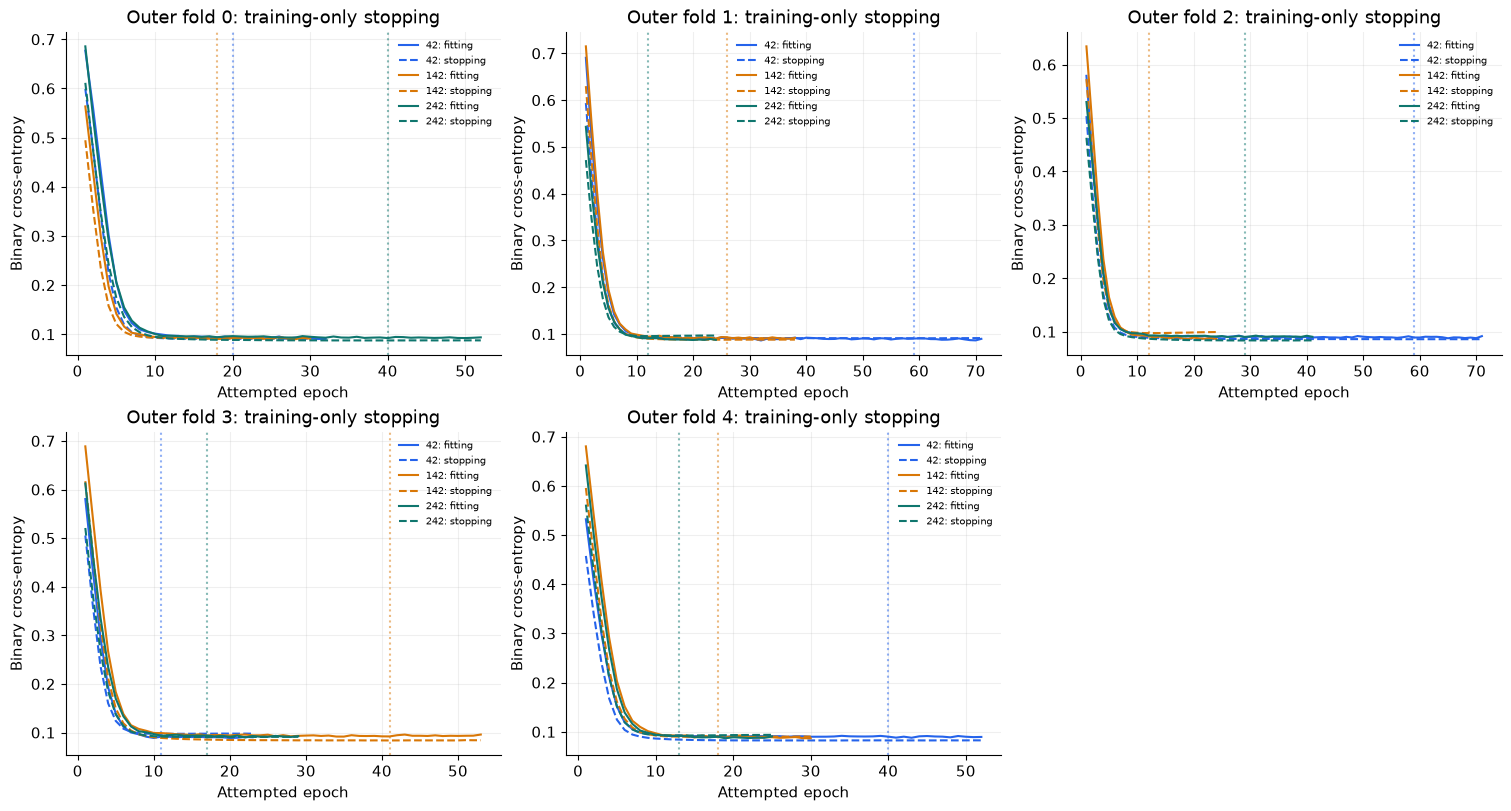

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout="constrained")
for fold, ax in enumerate(axes.flat[:5]):
    for index, seed in enumerate([42, 142, 242]):
        rows = history.loc[history.outer_fold.eq(fold) & history.base_seed.eq(seed) & history.phase.eq("stopping")]
        selected = int(epochs.loc[epochs.outer_fold.eq(fold) & epochs.base_seed.eq(seed), "selected_epochs"].iloc[0])
        ax.plot(rows.epoch, rows.fit_bce, color=COLORS[index], label=f"{seed}: fitting")
        ax.plot(rows.epoch, rows.stop_bce, "--", color=COLORS[index], label=f"{seed}: stopping")
        ax.axvline(selected, linestyle=":", color=COLORS[index], alpha=.5)
    ax.set(title=f"Outer fold {fold}: training-only stopping", xlabel="Attempted epoch", ylabel="Binary cross-entropy")
    ax.grid(alpha=.2); ax.legend(frameon=False, fontsize=7)
axes.flat[5].axis("off")
finish_figure(fig, "nn_fifteen_stopping_trajectories")

## 4. Read the fresh refit histories and selected durations

The outer refit runs for its selected duration using all four training folds. Only fitting BCE is available here; it must not be interpreted as validation performance. The duration table makes the workload and stopping-fold sensitivity visible without selecting a new duration from these plots.

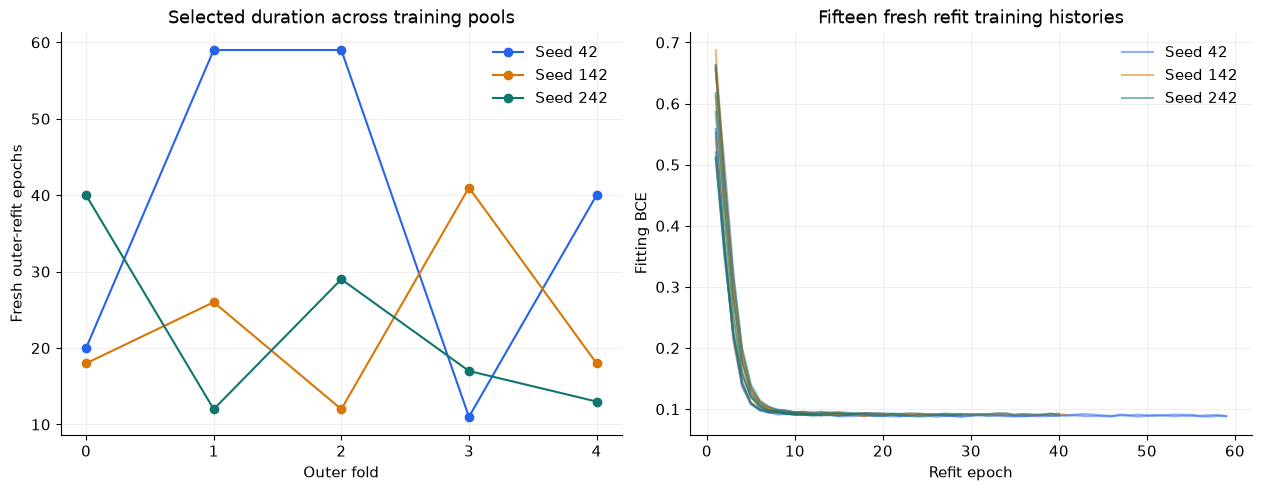

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), layout="constrained")
for index, seed in enumerate([42, 142, 242]):
    rows = epochs.loc[epochs.base_seed.eq(seed)]
    axes[0].plot(rows.outer_fold, rows.selected_epochs, "o-", color=COLORS[index], label=f"Seed {seed}")
    for fold in range(5):
        line = history.loc[history.base_seed.eq(seed) & history.outer_fold.eq(fold) & history.phase.eq("outer_refit")]
        axes[1].plot(line.epoch, line.fit_bce, color=COLORS[index], alpha=.5, label=f"Seed {seed}" if fold == 0 else None)
axes[0].set(title="Selected duration across training pools", xlabel="Outer fold", ylabel="Fresh outer-refit epochs", xticks=range(5))
axes[1].set(title="Fifteen fresh refit training histories", xlabel="Refit epoch", ylabel="Fitting BCE")
for ax in axes: ax.grid(alpha=.2); ax.legend(frameon=False)
finish_figure(fig, "nn_selected_epochs_and_refits")

## 5. Compare every seed and the prescribed ensemble

Report all seeds and their equal-mean ensemble rather than selecting the strongest seed. The primary bars use mean-fold AP and AUC; pooled results remain secondary. Sample variability over three runs reflects seed plus stopping-fold choices and is not a confidence interval for future patients.

,model,scope,fold,average_precision,roc_auc,log_loss,brier
5,spline_raw,mean_fold,NaN,0.06484,0.65563,0.09101,0.01842
6,spline_raw,pooled,NaN,0.04921,0.64283,0.09095,0.01841
12,nn_seed_42,mean_fold,NaN,0.05863,0.67325,0.09061,0.01840
13,nn_seed_42,pooled,NaN,0.04672,0.66062,0.09054,0.01839
19,nn_seed_142,mean_fold,NaN,0.05884,0.67409,0.09031,0.01838
20,nn_seed_142,pooled,NaN,0.04859,0.66933,0.09025,0.01837
26,nn_seed_242,mean_fold,NaN,0.05395,0.67562,0.09014,0.01840
27,nn_seed_242,pooled,NaN,0.04640,0.67177,0.09008,0.01839
33,metadata_nn_mean,mean_fold,NaN,0.05957,0.67669,0.09017,0.01838
34,metadata_nn_mean,pooled,NaN,0.04768,0.66946,0.09011,0.01837


,scope,metric,runs,mean,sample_std,minimum,maximum,range
0,mean_fold,average_precision,3,0.05714,0.00277,0.05395,0.05884,0.00489
1,mean_fold,roc_auc,3,0.67432,0.00120,0.67325,0.67562,0.00237
2,mean_fold,log_loss,3,0.09035,0.00023,0.09014,0.09061,0.00046
3,mean_fold,brier,3,0.01839,0.00001,0.01838,0.01840,0.00002
4,pooled,average_precision,3,0.04724,0.00118,0.04640,0.04859,0.00219
5,pooled,roc_auc,3,0.66724,0.00586,0.66062,0.67177,0.01114
6,pooled,log_loss,3,0.09029,0.00023,0.09008,0.09054,0.00046
7,pooled,brier,3,0.01838,0.00001,0.01837,0.01839,0.00002


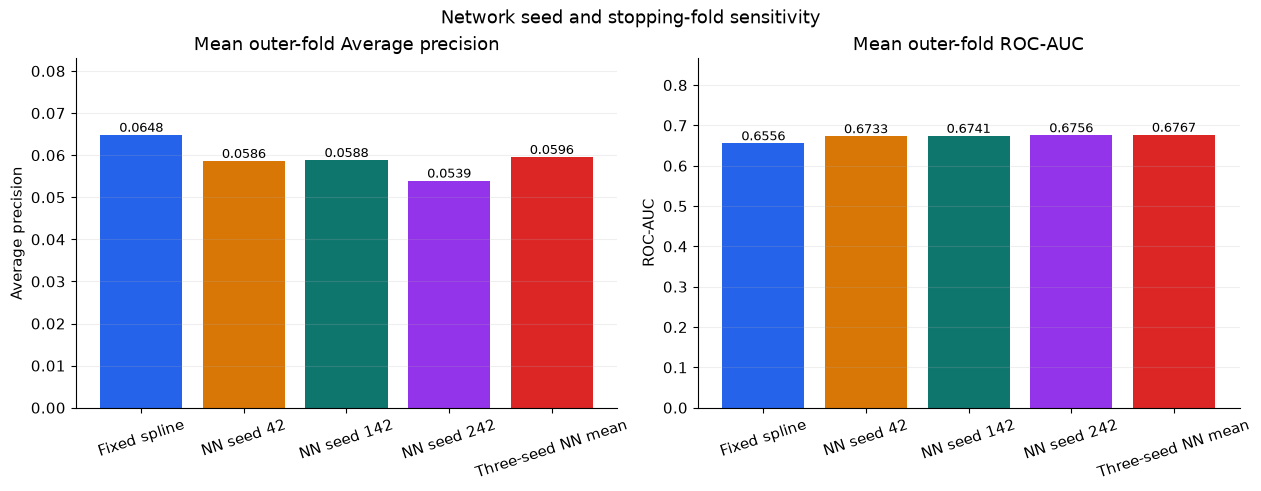

In [6]:
display(metrics.loc[metrics.scope.ne("fold")].round(5))
stability = []
for scope in ["mean_fold", "pooled"]:
    seed_rows = metrics.loc[metrics.scope.eq(scope) & metrics.model.str.startswith("nn_seed")]
    for metric in ["average_precision", "roc_auc", "log_loss", "brier"]:
        values = seed_rows[metric]
        stability.append({"scope": scope, "metric": metric, "runs": len(values), "mean": values.mean(), "sample_std": values.std(ddof=1), "minimum": values.min(), "maximum": values.max(), "range": values.max()-values.min()})
display(pd.DataFrame(stability).round(5))
finish_figure(metric_bar_figure(metrics, names, "Network seed and stopping-fold sensitivity"), "nn_seed_stability")

## 6. Verify the ensemble and inspect seed disagreement

The ensemble uses the equal mean of all three seed probabilities. Verify it within the float32 arithmetic precision of the saved NN inference and report the small numerical difference after CSV loading. Between-seed score spread is an exploratory stability diagnostic; it is not the later image MC-dropout uncertainty measure. Listed images are development review examples, not automatic exclusions or new training rules.

,Maximum float64 reconstruction difference,Saved inference arithmetic
0,1.166667e-08,float32 equal mean; original retained scores p...


,image_id,patient_id,fold,target,ensemble_score,seed_score_sd
2068,ISIC_3119175,IP_1210062,2,0,0.12672,0.06028
4162,ISIC_6159454,IP_1210062,2,0,0.12672,0.06028
2303,ISIC_3445468,IP_6215369,2,0,0.12092,0.05218
2852,ISIC_4263017,IP_0391953,2,0,0.12092,0.05218
1506,ISIC_2301843,IP_8326844,1,0,0.11975,0.04965
2608,ISIC_3876274,IP_3846489,1,0,0.10449,0.04042
3298,ISIC_4954740,IP_0444327,1,0,0.10449,0.04042
1440,ISIC_2215830,IP_7716159,1,0,0.09784,0.03756
1508,ISIC_2306349,IP_9092661,1,1,0.09784,0.03756
3052,ISIC_4565629,IP_3370847,1,0,0.09486,0.03731


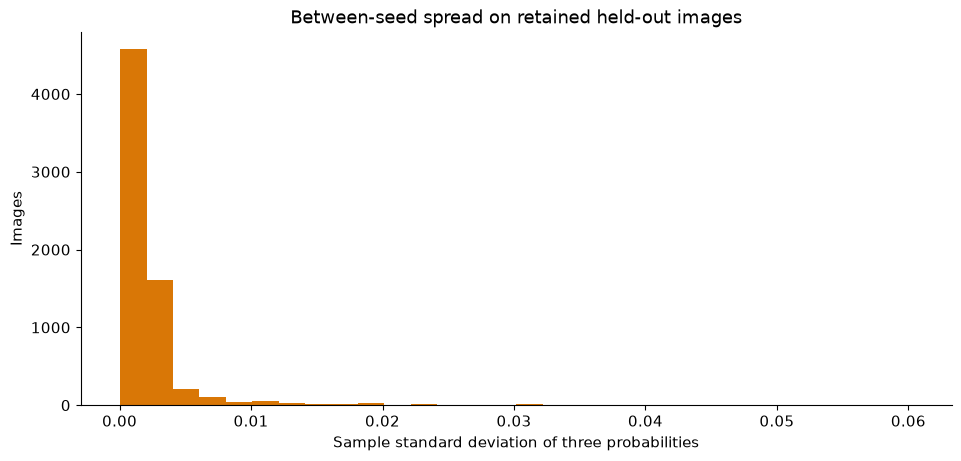

In [7]:
seed_values = np.column_stack([scores[f"nn_seed_{seed}"] for seed in [42, 142, 242]])
mean_difference = float(np.max(np.abs(seed_values.mean(axis=1) - scores["metadata_nn_mean"])))
assert np.allclose(seed_values.mean(axis=1), scores["metadata_nn_mean"], rtol=2*np.finfo(np.float32).eps, atol=1e-8)
display(pd.DataFrame([{"Maximum float64 reconstruction difference": mean_difference, "Saved inference arithmetic": "float32 equal mean; original retained scores preserved"}]))
review = frame[["image_id", "patient_id", "fold", "target"]].copy()
review["ensemble_score"] = scores["metadata_nn_mean"]
review["seed_score_sd"] = seed_values.std(axis=1, ddof=1)
display(review.sort_values(["seed_score_sd", "image_id"], ascending=[False, True]).head(12).round(5))
fig, ax = plt.subplots(figsize=(9.5, 4.5), layout="constrained")
ax.hist(review.seed_score_sd, bins=30, color="#d97706")
ax.set(title="Between-seed spread on retained held-out images", xlabel="Sample standard deviation of three probabilities", ylabel="Images")
finish_figure(fig, "nn_between_seed_disagreement")

## 7. Read held-out curves and the supported conclusion

Read the NN and spline at a common recall; a higher AP is not a calibrated risk or a clinical decision rule. Notebook 08 supplies the paired whole-patient interval for NN mean minus fixed spline. These curves and seed diagnostics do not justify replacing the primary model by whichever seed looks best.

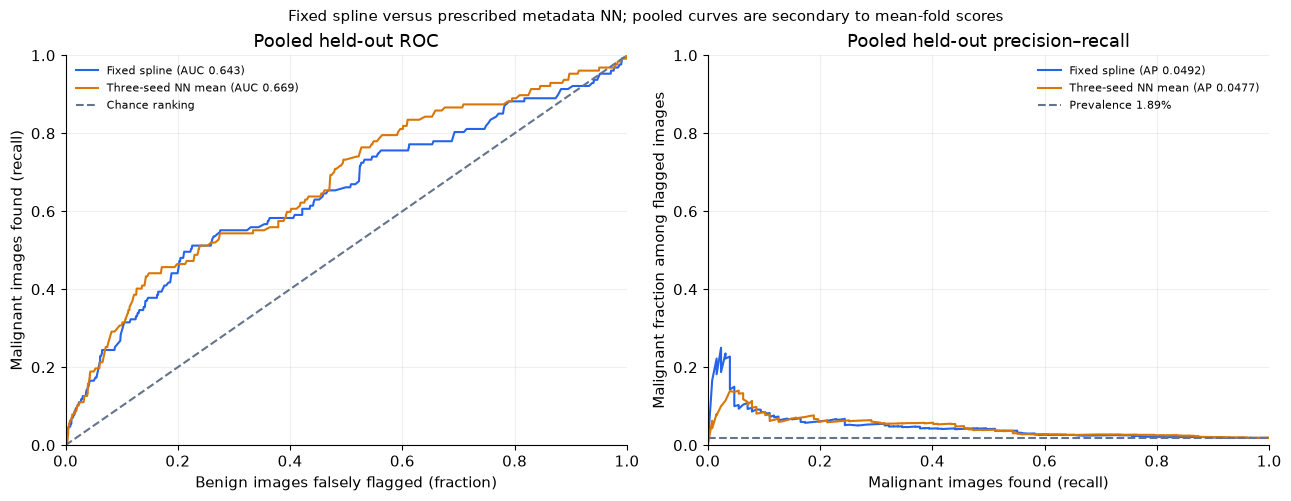

All three prescribed runs are included. Stopping and refit histories are complete; outer predictions remain held out by patient. Probability calibration, decision support and paired intervals follow in notebook 08.

In [8]:
finish_figure(curve_figure(frame, scores, ["spline_raw", "metadata_nn_mean"], "Fixed spline versus prescribed metadata NN"), "nn_spline_roc_pr")
display(Markdown("All three prescribed runs are included. Stopping and refit histories are complete; outer predictions remain held out by patient. Probability calibration, decision support and paired intervals follow in notebook 08."))

## Interpretation boundary

These are development results. Patient grouping protects separation between fitting and validation; bootstrap intervals condition on saved models. Sparse subgroups and selected inner-validation pilots cannot establish a final winner. No reserved-test conclusion is made.